# Exploratory Data Analysis: UCI Heart Disease Risk Factors

**Author:** Antigravity Data Science & ML Engineering Team  
**Dataset:** Cleveland Clinic Foundation Heart Disease Dataset (UCI ML Repository ID: 45)  
**Objective:** Characterize patient demographic, clinical, electrocardiographic, and scintigraphic features associated with the angiographic presence of coronary artery disease.

---

### Clinical & Educational Disclaimer
*This exploratory analysis is conducted for academic, educational, and portfolio purposes. Observational correlations identified in this dataset reflect patterns within the historical Cleveland Clinic patient sample and must not be interpreted as causal relationships or medical diagnostic criteria.*


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', None)

print('Libraries loaded successfully!')


Libraries loaded successfully!


## 1. Data Ingestion & Structural Inspection

We load the standardized dataset from `data/heart_disease.csv` (or the official UCI endpoint).
The dataset consists of 303 patient observations across 14 clinical features and one binary classification target.


In [2]:
data_path = os.path.join('..', 'data', 'heart_disease.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'heart_disease.csv')

df = pd.read_csv(data_path)
print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Dimensions: 303 rows, 15 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0,0


In [3]:
# Schema and data type inspection
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
 14  target    303 non-null    int64  
dtypes: float64(3), int64(12)
memory usage: 35.6 KB


## 2. Data Integrity: Missing Values and Duplicate Records

In the original Cleveland dataset, clinical records recorded missing measurements for `ca` (number of vessels colored by fluoroscopy) and `thal` (thallium nuclear stress test status).


In [4]:
# Check missing values
missing = df.isnull().sum()
missing = missing[missing > 0]
print('Features with missing records:')
print(missing)

# Check duplicate records
duplicate_count = df.duplicated().sum()
print(f'\nDuplicate records found: {duplicate_count}')


Features with missing records:
ca      4
thal    2
dtype: int64

Duplicate records found: 0


## 3. Target Distribution: Angiographic Disease Status

In the raw dataset, `num` represents coronary diameter narrowing:
- `0`: `< 50%` diameter narrowing (Absence of significant angiographic disease)
- `1, 2, 3, 4`: `> 50%` diameter narrowing across 1 to 4 coronary vessels.

Binary target `target` groups all values `> 0` into class `1` (Presence of Disease).


C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\2911907140.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=raw_counts.index, y=raw_counts.values, palette='Blues_d', ax=ax1, edgecolor='#ffffff')


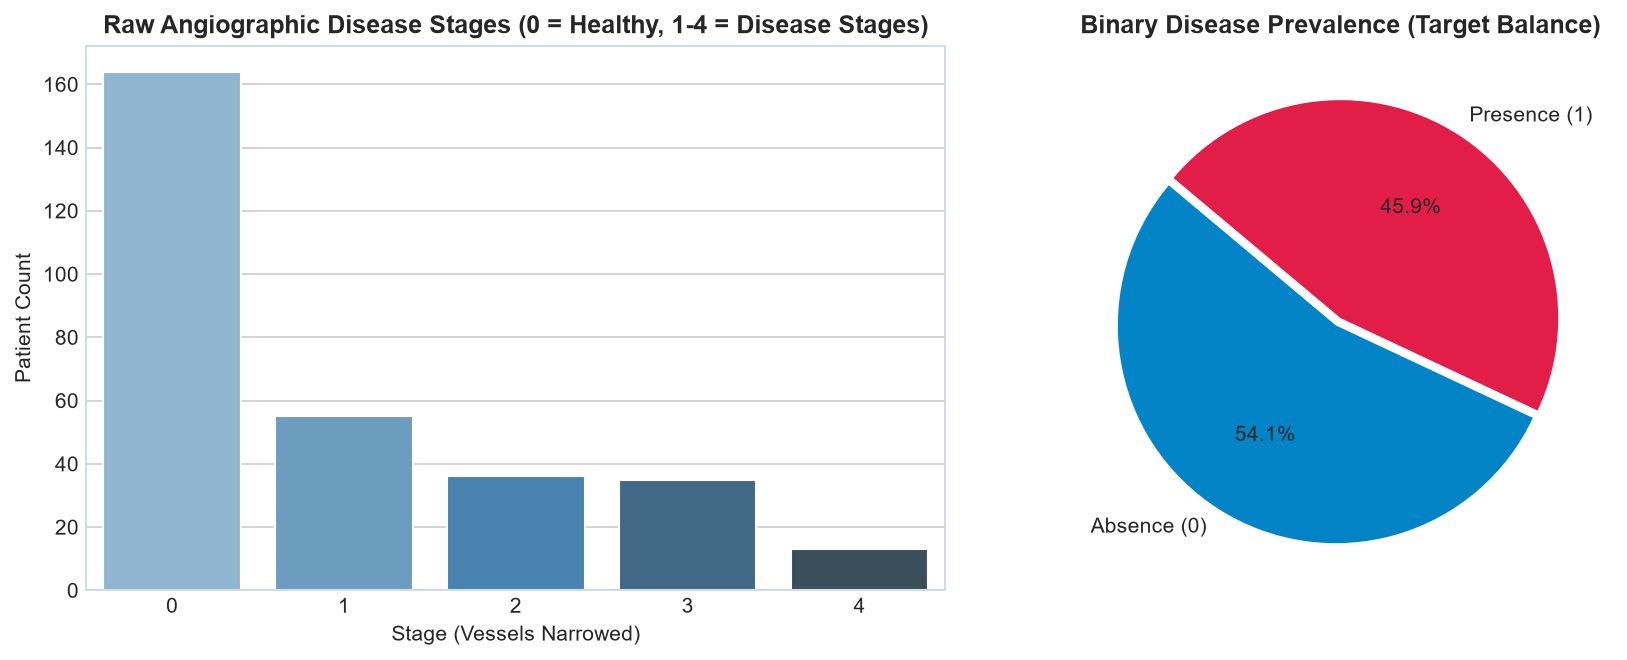

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

# Multi-class target
raw_counts = df['num'].value_counts().sort_index()
sns.barplot(x=raw_counts.index, y=raw_counts.values, palette='Blues_d', ax=ax1, edgecolor='#ffffff')
ax1.set_title('Raw Angiographic Disease Stages (0 = Healthy, 1-4 = Disease Stages)', fontweight='bold')
ax1.set_xlabel('Stage (Vessels Narrowed)')
ax1.set_ylabel('Patient Count')

# Binary target
target_counts = df['target'].value_counts()
labels = ['Absence (0)', 'Presence (1)']
ax2.pie(target_counts, labels=labels, autopct='%1.1f%%', colors=['#0284c7', '#e11d48'], startangle=140, explode=(0.04, 0))
ax2.set_title('Binary Disease Prevalence (Target Balance)', fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Demographic Analysis: Age and Sex Distributions

Age is an established physiological determinant of arterial stiffening, while sex-specific hormonal and vascular differences influence coronary presentation.


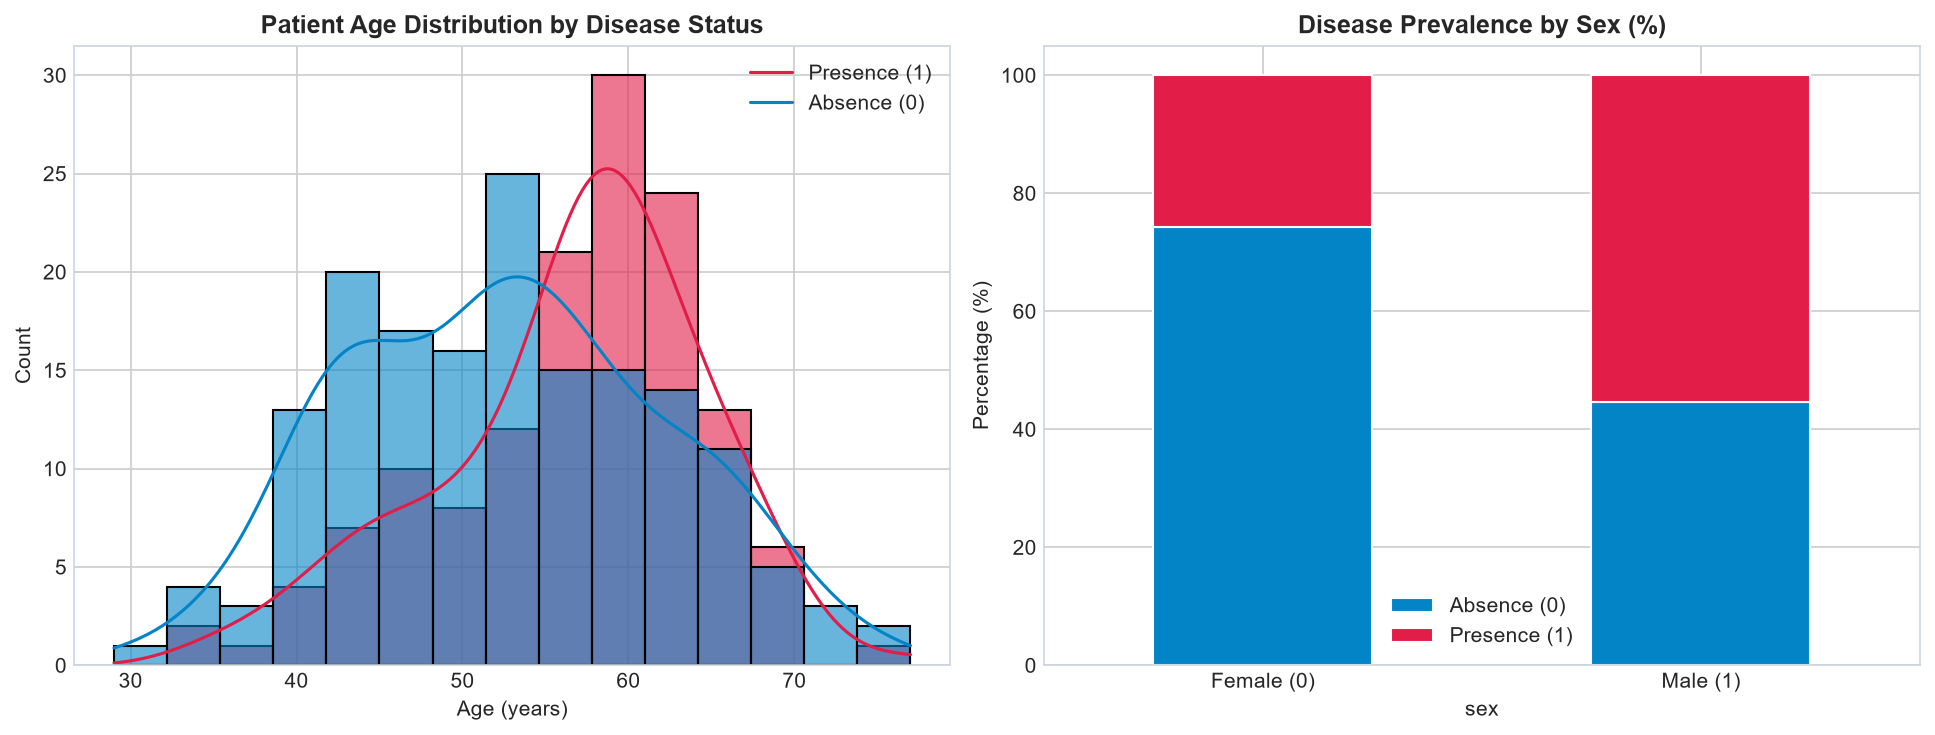

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Age distribution by target
sns.histplot(data=df, x='age', hue='target', kde=True, palette={0: '#0284c7', 1: '#e11d48'}, ax=ax1, bins=15, alpha=0.6)
ax1.set_title('Patient Age Distribution by Disease Status', fontweight='bold')
ax1.set_xlabel('Age (years)')
ax1.legend(['Presence (1)', 'Absence (0)'])

# Sex vs Disease
sex_ct = pd.crosstab(df['sex'], df['target'], normalize='index') * 100
sex_ct.plot(kind='bar', stacked=True, color=['#0284c7', '#e11d48'], ax=ax2, edgecolor='#ffffff')
ax2.set_title('Disease Prevalence by Sex (%)', fontweight='bold')
ax2.set_xticklabels(['Female (0)', 'Male (1)'], rotation=0)
ax2.set_ylabel('Percentage (%)')
ax2.legend(['Absence (0)', 'Presence (1)'])

plt.tight_layout()
plt.show()


## 5. Hemodynamic & Metabolic Indicators: Blood Pressure and Cholesterol

Analyzing resting systolic blood pressure (`trestbps`) and serum cholesterol (`chol`).


C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\4105770852.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='trestbps', palette=['#0284c7', '#e11d48'], ax=ax1)
C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\4105770852.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(['Absence (0)', 'Presence (1)'])
C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\4105770852.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='chol', palette=['#0284c7', '#e11d48'], ax=ax2)
C:\Users\jeeva\AppData\Local\Temp\ipyker

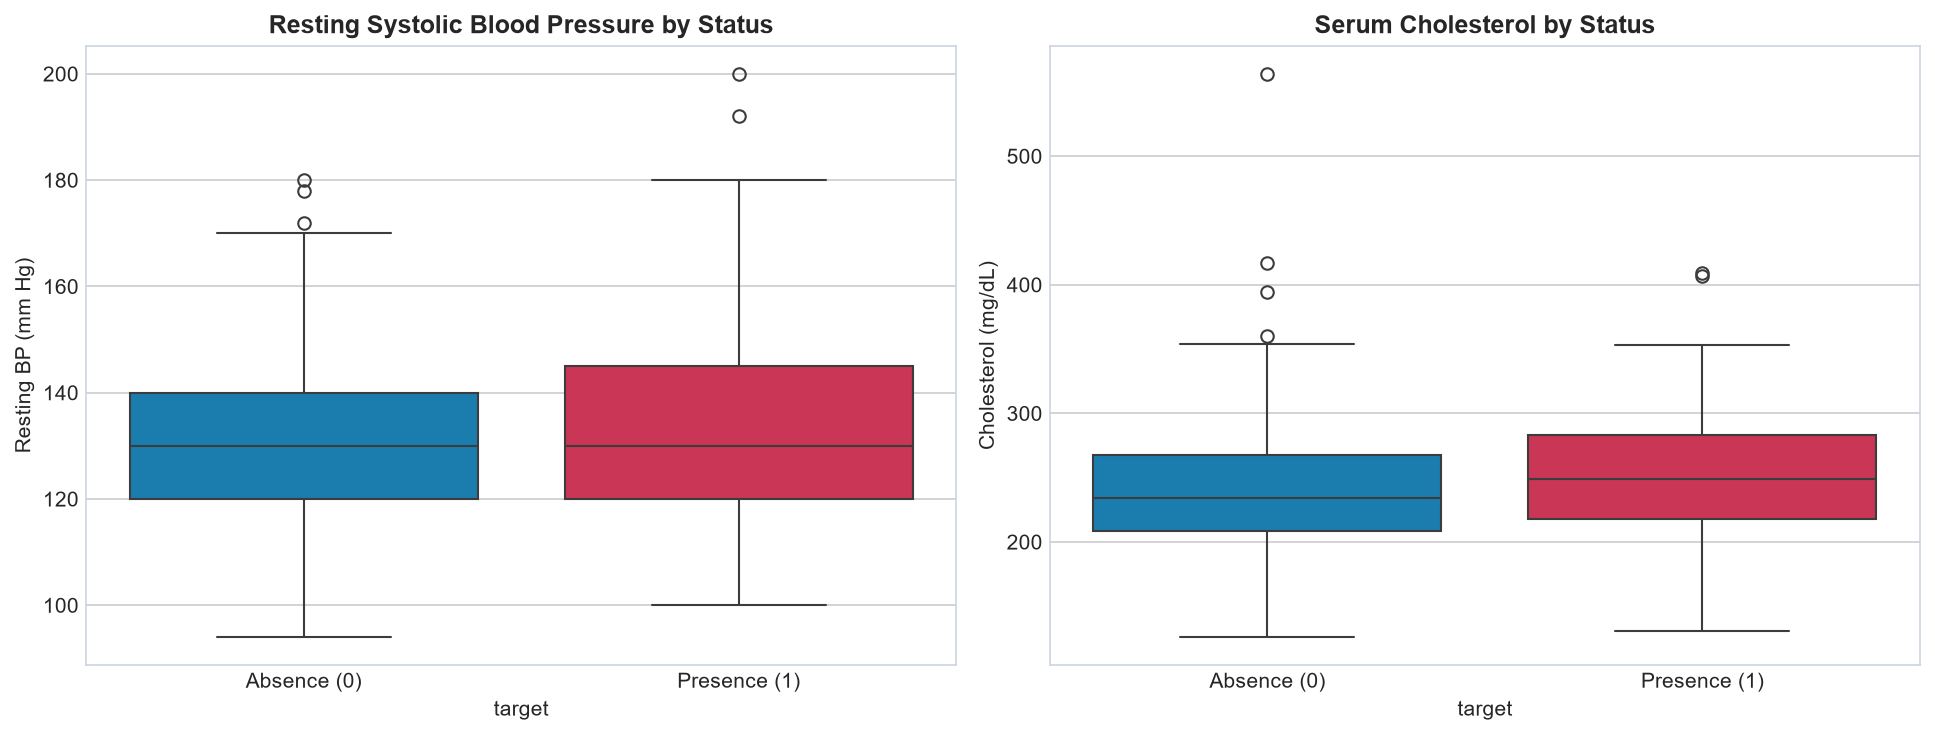

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

sns.boxplot(data=df, x='target', y='trestbps', palette=['#0284c7', '#e11d48'], ax=ax1)
ax1.set_title('Resting Systolic Blood Pressure by Status', fontweight='bold')
ax1.set_xticklabels(['Absence (0)', 'Presence (1)'])
ax1.set_ylabel('Resting BP (mm Hg)')

sns.boxplot(data=df, x='target', y='chol', palette=['#0284c7', '#e11d48'], ax=ax2)
ax2.set_title('Serum Cholesterol by Status', fontweight='bold')
ax2.set_xticklabels(['Absence (0)', 'Presence (1)'])
ax2.set_ylabel('Cholesterol (mg/dL)')

plt.tight_layout()
plt.show()


## 6. Electrocardiographic Stress Indicators: ST Depression, Slope & Angina

During cardiac stress testing, ischemia is signaled by exercise-induced angina (`exang`), maximum achieved heart rate (`thalach`), and ST-segment depression (`oldpeak`).


C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\2512875860.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='oldpeak', palette=['#0284c7', '#e11d48'], ax=ax2)
C:\Users\jeeva\AppData\Local\Temp\ipykernel_23444\2512875860.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(['Absence (0)', 'Presence (1)'])


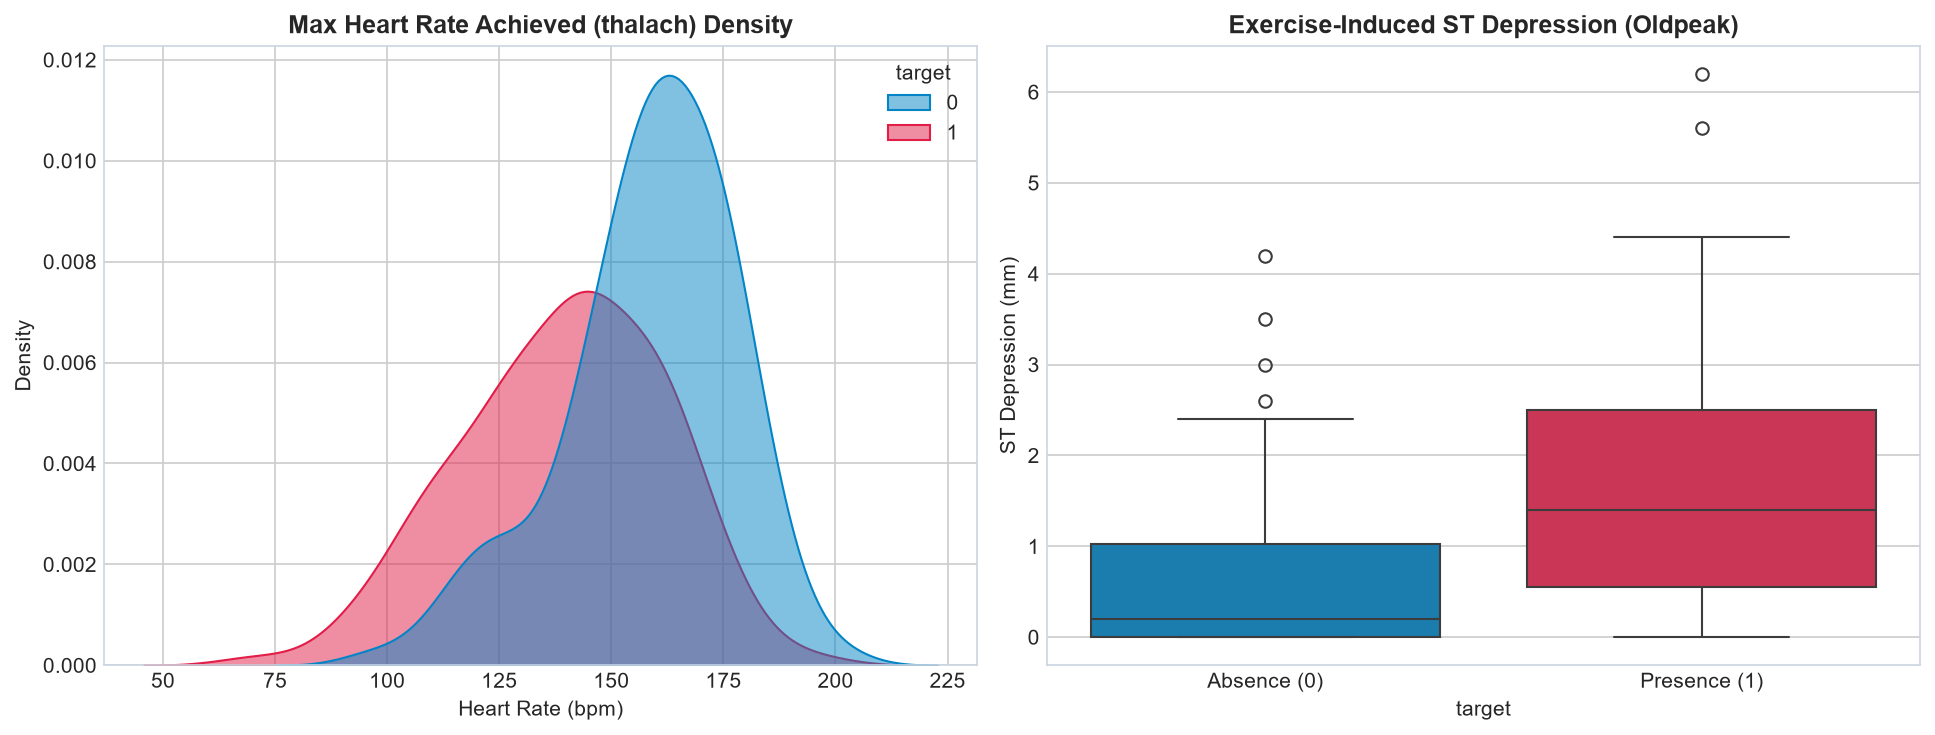

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Max Heart Rate Achieved
sns.kdeplot(data=df, x='thalach', hue='target', fill=True, palette={0: '#0284c7', 1: '#e11d48'}, ax=ax1, alpha=0.5)
ax1.set_title('Max Heart Rate Achieved (thalach) Density', fontweight='bold')
ax1.set_xlabel('Heart Rate (bpm)')

# ST Depression (oldpeak)
sns.boxplot(data=df, x='target', y='oldpeak', palette=['#0284c7', '#e11d48'], ax=ax2)
ax2.set_title('Exercise-Induced ST Depression (Oldpeak)', fontweight='bold')
ax2.set_xticklabels(['Absence (0)', 'Presence (1)'])
ax2.set_ylabel('ST Depression (mm)')

plt.tight_layout()
plt.show()


## 7. Diagnostic Testing: Fluoroscopy Vessels & Thallium Scintigraphy

Coronary fluoroscopy (`ca`) reveals macroscopic arterial calcification, while Thallium-201 scintigraphy (`thal`) detects myocardial perfusion defects.


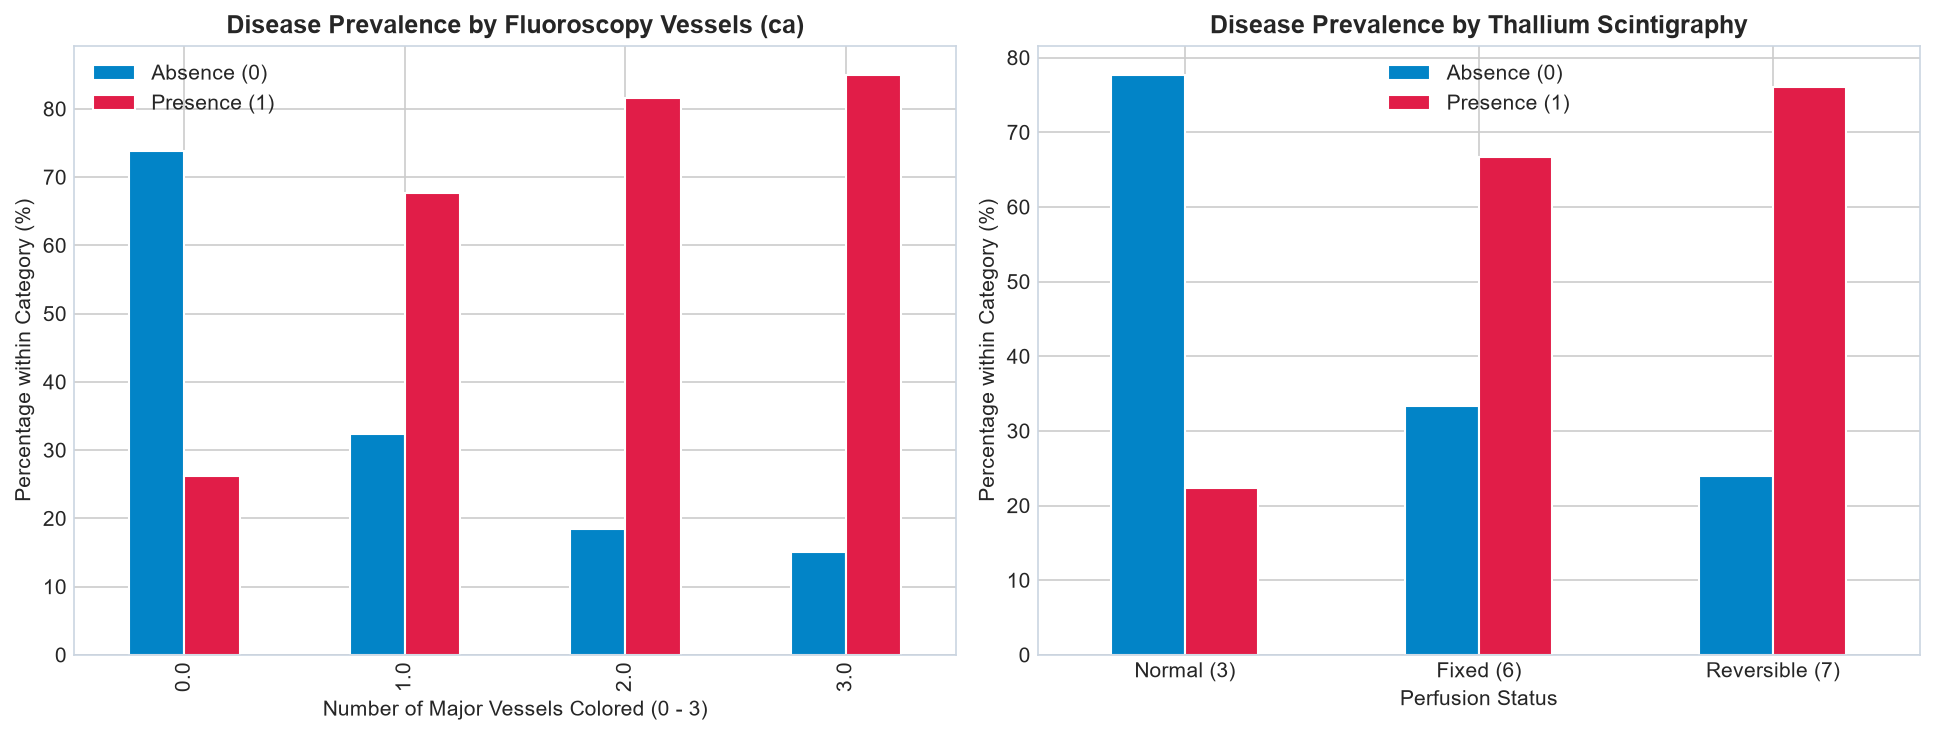

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Major Vessels Colored (ca)
ca_ct = pd.crosstab(df['ca'], df['target'], normalize='index') * 100
ca_ct.plot(kind='bar', color=['#0284c7', '#e11d48'], ax=ax1, edgecolor='#ffffff')
ax1.set_title('Disease Prevalence by Fluoroscopy Vessels (ca)', fontweight='bold')
ax1.set_xlabel('Number of Major Vessels Colored (0 - 3)')
ax1.set_ylabel('Percentage within Category (%)')
ax1.legend(['Absence (0)', 'Presence (1)'])

# Thalassemia status (thal)
thal_ct = pd.crosstab(df['thal'], df['target'], normalize='index') * 100
thal_ct.plot(kind='bar', color=['#0284c7', '#e11d48'], ax=ax2, edgecolor='#ffffff')
ax2.set_title('Disease Prevalence by Thallium Scintigraphy', fontweight='bold')
ax2.set_xticklabels(['Normal (3)', 'Fixed (6)', 'Reversible (7)'], rotation=0)
ax2.set_xlabel('Perfusion Status')
ax2.set_ylabel('Percentage within Category (%)')
ax2.legend(['Absence (0)', 'Presence (1)'])

plt.tight_layout()
plt.show()


## 8. Correlation Matrix & Feature Interdependencies

We inspect linear and rank correlation across numerical attributes and the binary classification target.


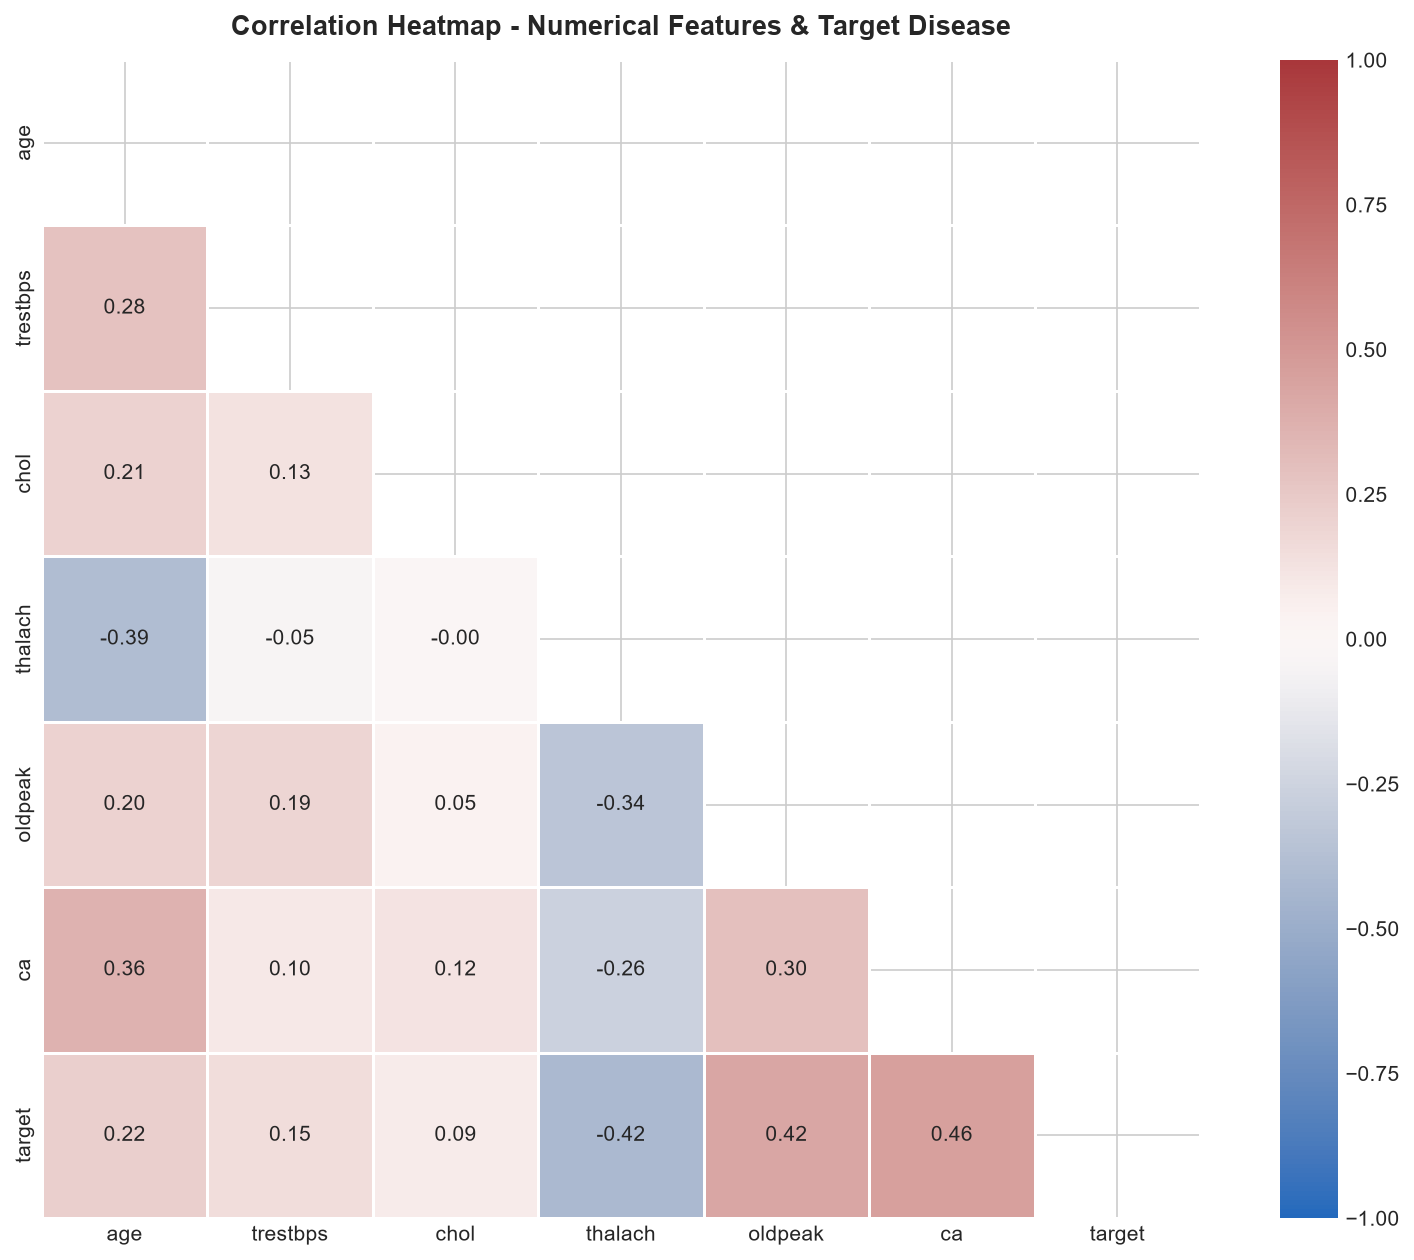

In [10]:
plt.figure(figsize=(11, 8.5), dpi=150)
numeric_df = df[['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'target']].copy()
corr = numeric_df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Heatmap - Numerical Features & Target Disease', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 9. Summary of Exploratory Observations

1. **Fluoroscopy (`ca`) & Thallium Scintigraphy (`thal`):** Display the strongest individual associations with coronary disease. Over 80% of patients with $\ge 1$ fluoroscopy-opacified vessel had confirmed angiographic disease. Reversible thallium perfusion defects (`thal = 7`) likewise correlated with high disease prevalence.
2. **Exercise Electrocardiography (`oldpeak`, `thalach`, `exang`):** Exercise-induced ST depression $\ge 1.5$ mm and presence of exertional angina strongly distinguish patients with angiographic stenosis. Maximum achievable heart rate is noticeably depressed in diseased cohorts (chronotropic incompetence).
3. **Age & Sex:** Disease prevalence rises monotonically after age 50. Male patients presented disease at a higher rate within this catheterization referral sample.
4. **Target Balance:** Unlike population-level screening datasets with extreme imbalance, the Cleveland cohort is balanced (54.1% negative, 45.9% positive), allowing reliable training with standard classification objectives.
